# Performance evaluation for **Xengsort**

## 0. Imports and path assignments

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

from warnings import simplefilter
simplefilter("ignore")

In [2]:
# --- Parameters ---
data_dir = Path.cwd().parent / "data"
method = "xengsort_newindex"
fig_dir = Path.cwd() / "figures" / method
fig_dir.mkdir(exist_ok=True, parents=True)

## 1. Load data

In [3]:
df = read_evaluations(data_dir, method)
df.groupby(["Sample_Prefix", "Total_Reads"]).count()
#df["Mixture"] = [f"{(int(mix_num*100))}p" for mix_num in df["Mixture"]]

ID  Mixture  \
Sample_Prefix                                      Total_Reads                
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000     54       54   
                                                   100000000    54       54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000     54       54   
                                                   100000000    54       54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000     54       54   
                                                   100000000    54       54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000     54       54   
                                                   100000000    54       54   

                                                                Replicate  \
Sample_Prefix                                      Total_Reads              
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000            54   
                                                   100000000           54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000            54   
                                                   100000000           54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000            54   
                                                   100000000           54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000            54   
                                                   100000000           54   

                                                                Human_Assigned  \
Sample_Prefix                                      Total_Reads                   
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   

                                                                Mouse_Assigned  \
Sample_Prefix                                      Total_Reads                   
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   

                                                                Amb_Assigned  \
Sample_Prefix                                      Total_Reads                 
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000               54   
                                                   100000000              54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000               54   
                                                   100000000              54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000               54   
                                                   100000000              54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000               54   
                                                   100000000              54   

                                                           

## Visualize assigned reads

sns.pointplot(
    data=df,
    x="Method",
    y="Precision",
    errorbar="sd",      # "ci", "sd", or ("pi", 95)
    palette=dkfz_colors,
    join=False,
    dodge=True
)


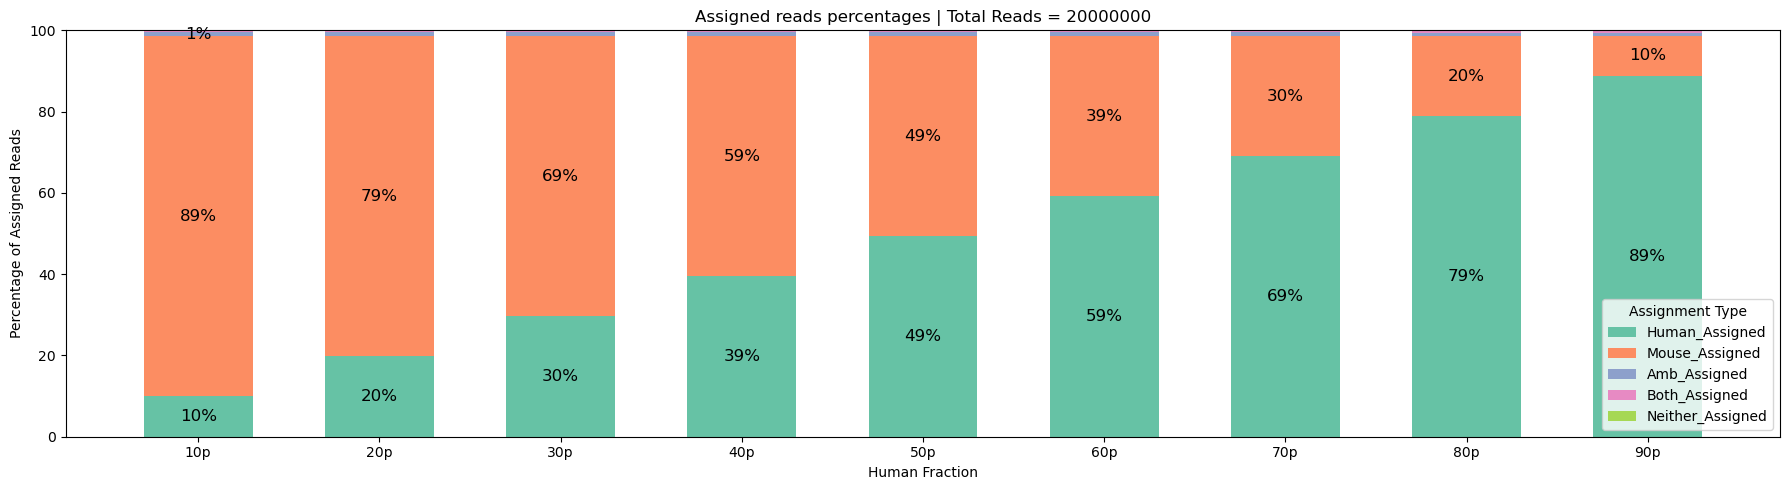

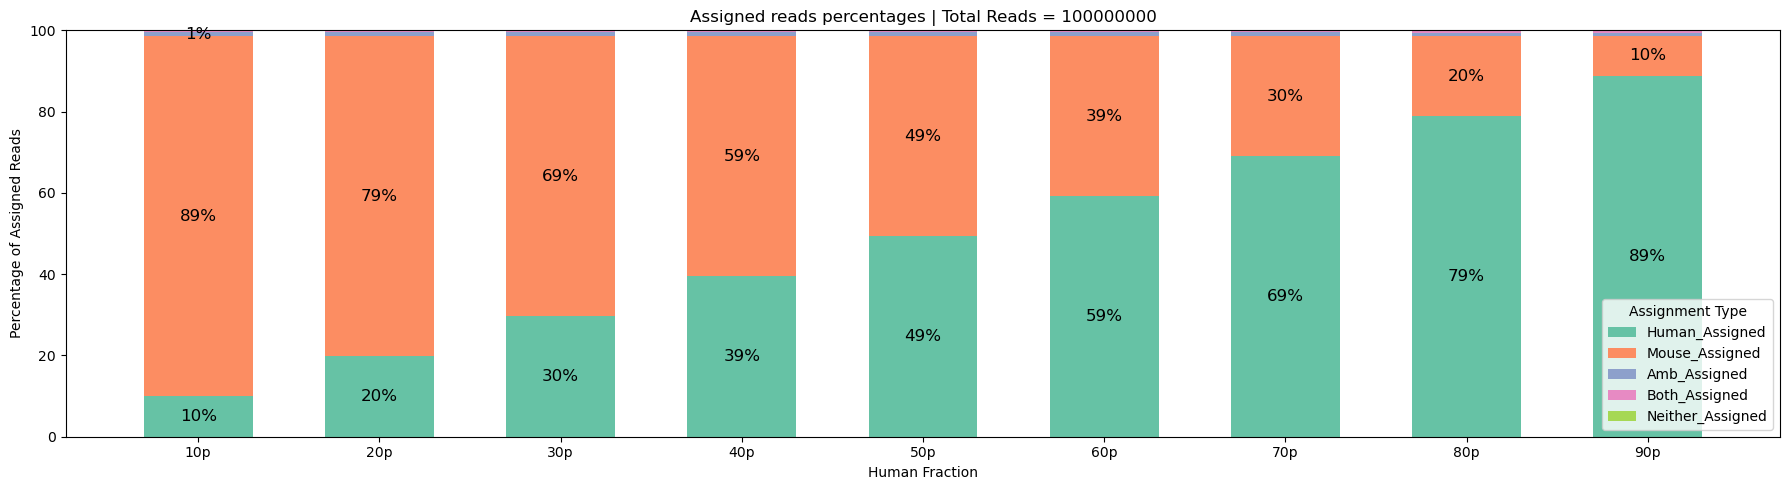

In [6]:

plot_assignment_bars_by_total_reads_stacked(df, assigned_cols=["Human_Assigned", "Mouse_Assigned", "Amb_Assigned", "Both_Assigned", "Neither_Assigned"])

In [7]:
df.iloc[0][["Mouse_Human", "Amb_Human", "Neither_Human", "Both_Human"]].sum() / df.iloc[0]["Total_Reads"] 

np.float64(0.005549)

## Confusion Matrix

In [4]:
df_conf = assign_confusion_matrix(df, method="xengsort")

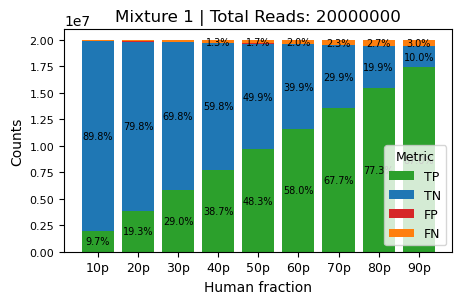

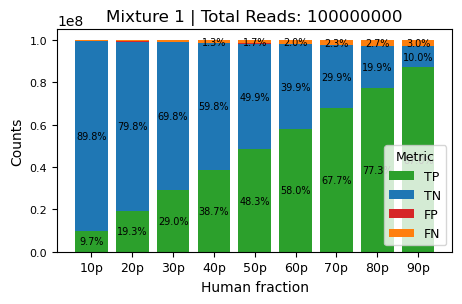

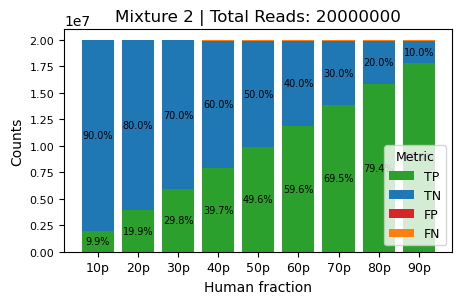

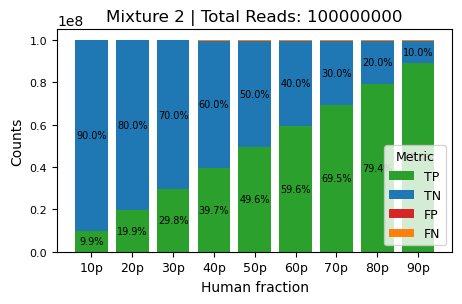

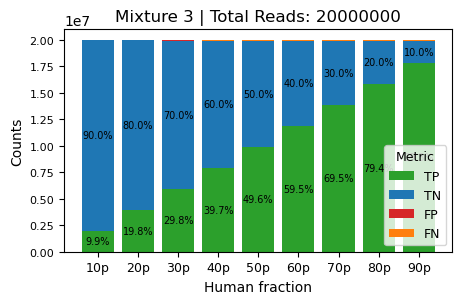

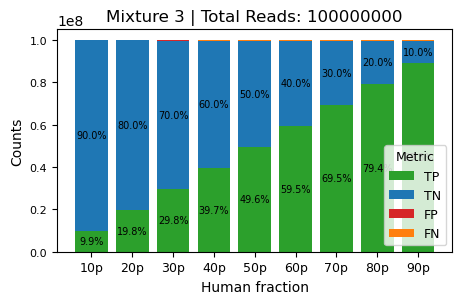

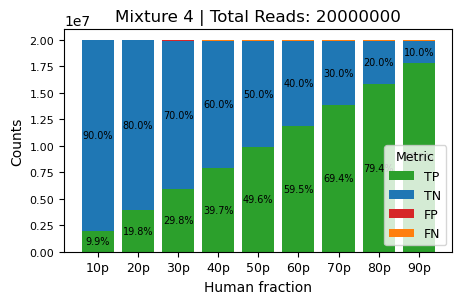

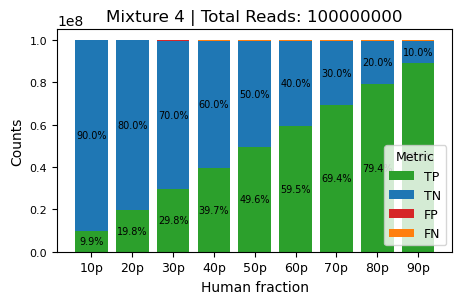

In [12]:
figsize = mm_to_inches((120, 80))
plot_confusion_bar(
    df_conf,
    save=True,
    fig_dir=fig_dir,
    figsize=figsize,
    xlabel_size=10,
    ylabel_size=10,
    xtick_size=9,
    ytick_size=8,
    annotation_size=7
)
#plot_confusion_matrix(df, save=True, fig_dir=fig_dir)

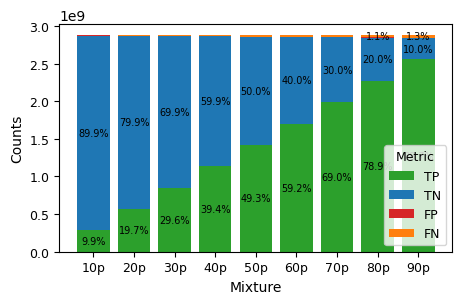

In [13]:
plot_stacked_confusion_bar(
    df_conf,
    save=False,
    figsize= figsize,
    xlabel_size=10,
    ylabel_size=10,
    xtick_size=9,
    ytick_size=9,
    annotation_size=7,
    legend_size=9)

## Calculate performance metrics

In [5]:
df_metrics = calculate_metrics(df_conf)
df_metrics.head(3)

,ID,Sample_Prefix,Total_Reads,Mixture,Replicate,Human_Assigned,Mouse_Assigned,Amb_Assigned,Both_Assigned,Neither_Assigned,...,Recall,FPR,Precision,F1,MCC,Human_Loss,Contamination_Rate,Mouse_Leakage,Human_Ratio,Score
0,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,0,13891342,5945120,106482,27992,29064,...,0.992073,0.000387,0.999833,0.995938,0.986663,0.007927,0.000167,0.000387,0.7,0.997505
1,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,1,13891758,5944926,106666,27824,28826,...,0.992108,0.000374,0.999838,0.995958,0.986730,0.007892,0.000162,0.000374,0.7,0.997519
2,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,2,13891670,5945632,105790,28302,28606,...,0.992101,0.000376,0.999838,0.995954,0.986717,0.007899,0.000162,0.000376,0.7,0.997517


In [7]:
df_metrics[["Contamination_Rate", "Precision"]]

,Contamination_Rate,Precision
0,0.000167,0.999833
1,0.000162,0.999838
2,0.000162,0.999838
3,0.000170,0.999830
4,0.000169,0.999831
...,...,...
427,0.000084,0.999916
428,0.000081,0.999919
429,0.000085,0.999915
430,0.000086,0.999914


## Visualize performance metrics

### Human Loss

### By total reads, for each sample

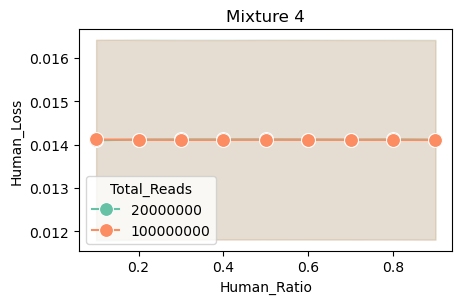

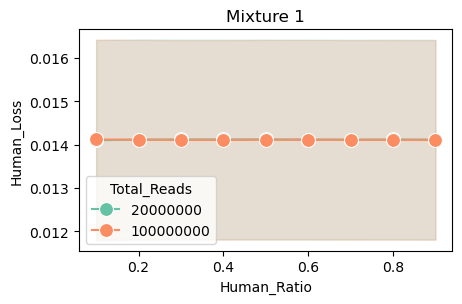

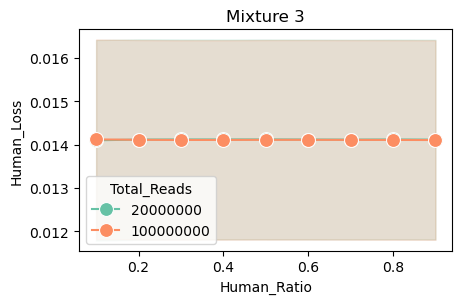

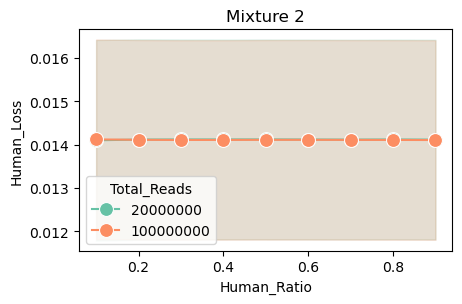

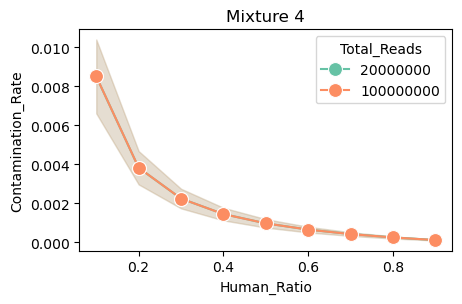

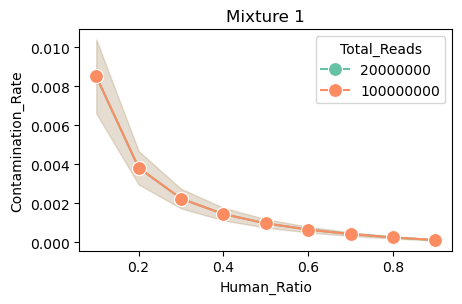

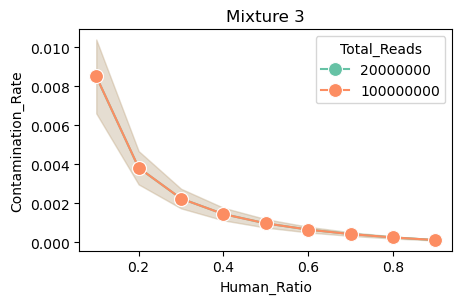

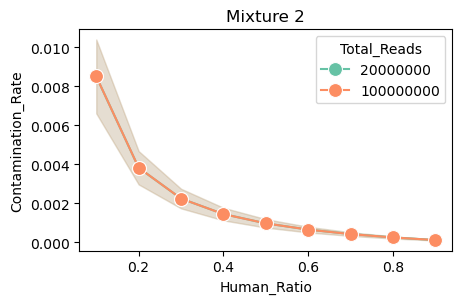

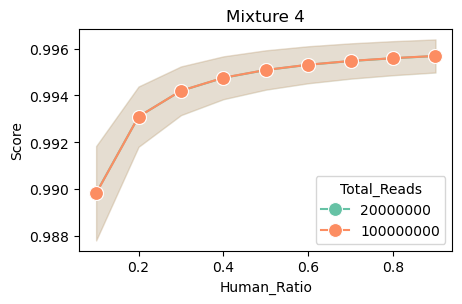

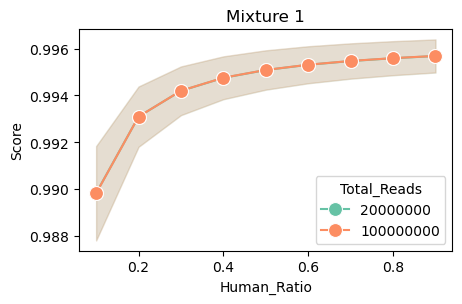

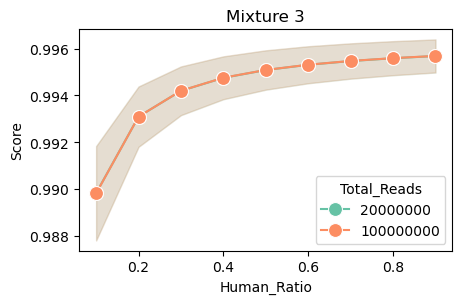

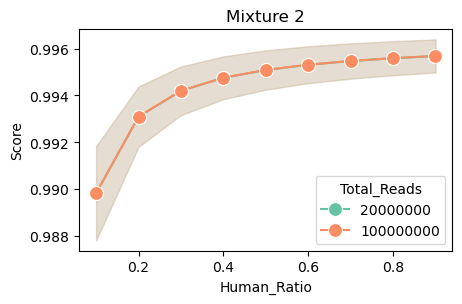

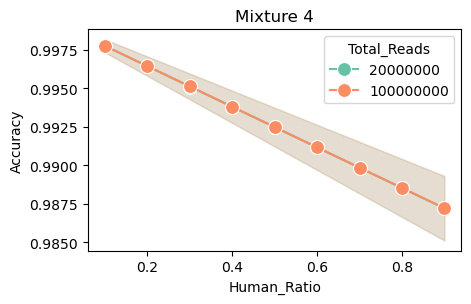

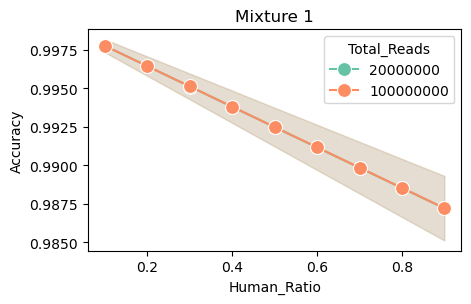

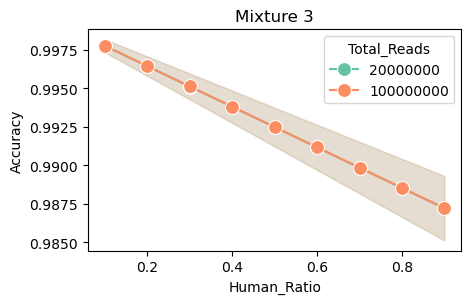

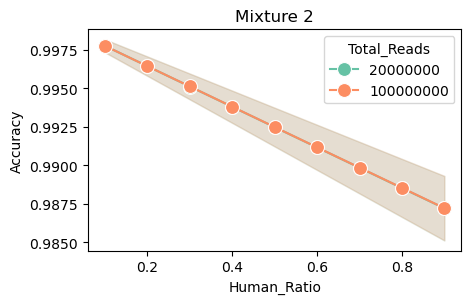

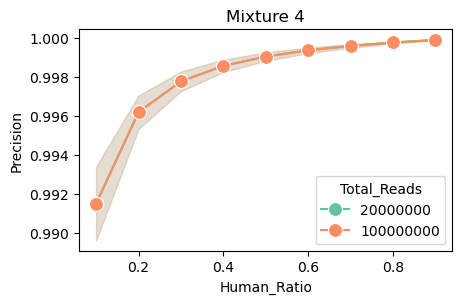

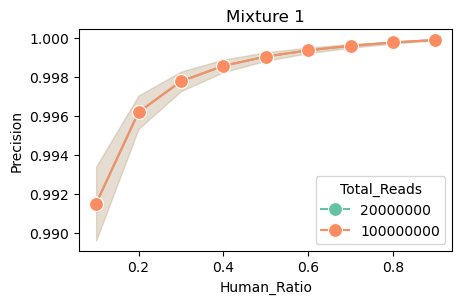

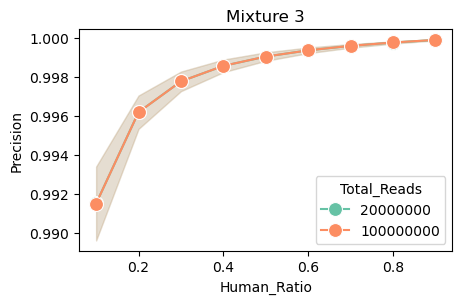

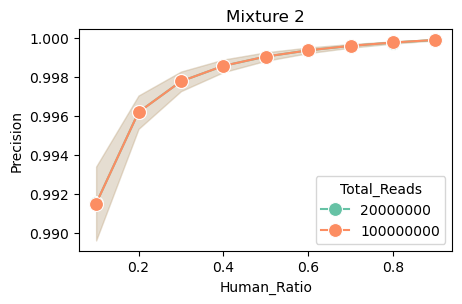

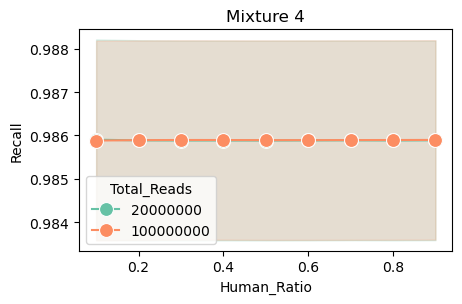

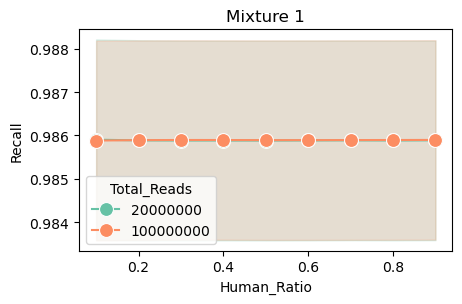

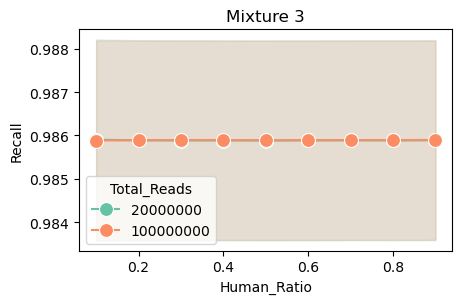

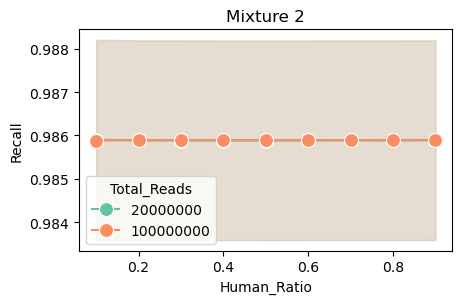

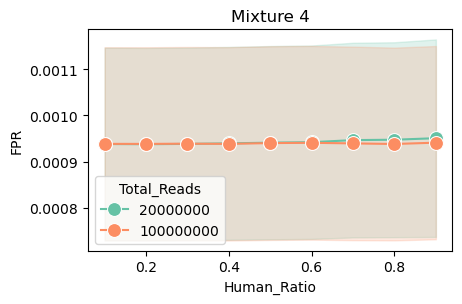

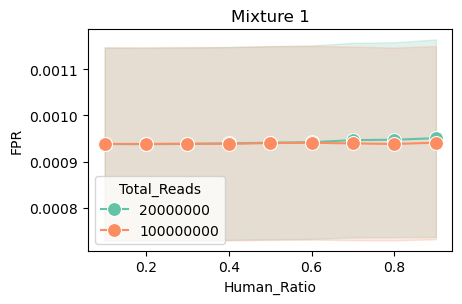

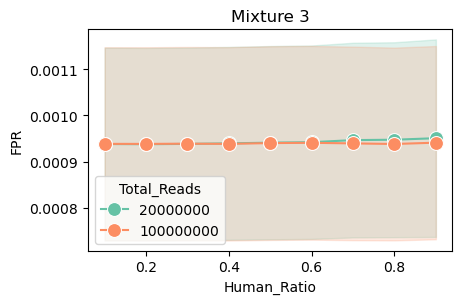

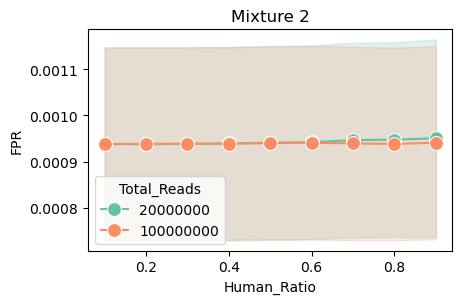

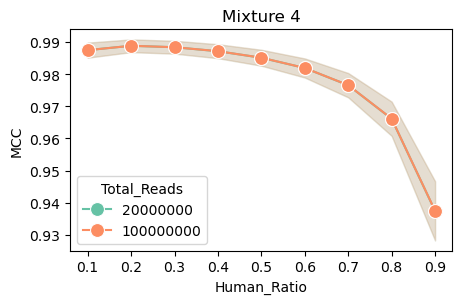

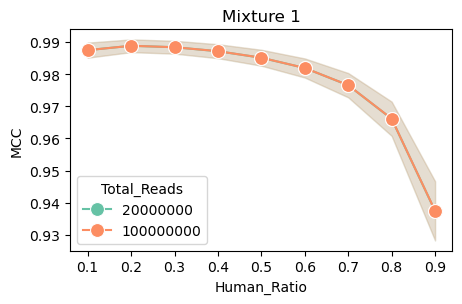

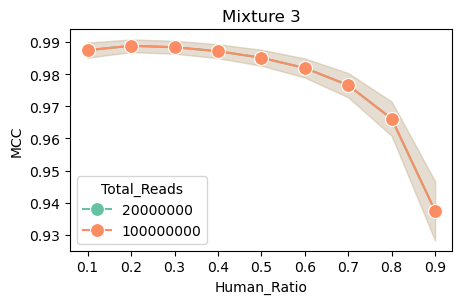

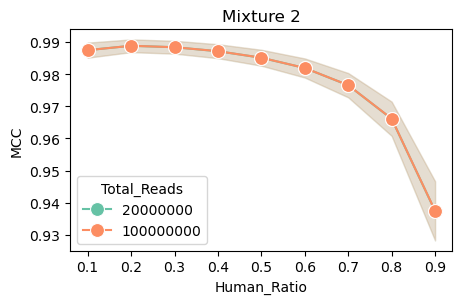

In [18]:
metrics = ["Human_Loss", "Contamination_Rate", "Score", "Accuracy", "Precision", "Recall", "FPR", "MCC"]
figsize=mm_to_inches((120, 80))
for metric in metrics:
    errorplot_by_reads(df_metrics, metric=metric, save=True, fig_dir=fig_dir, figsize=figsize, palette="Set2")


### Across samples

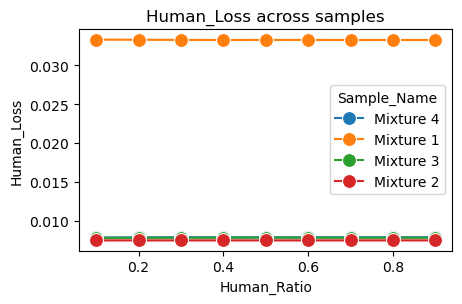

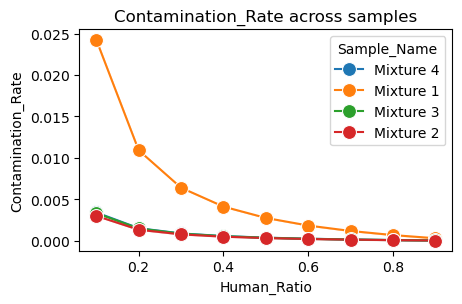

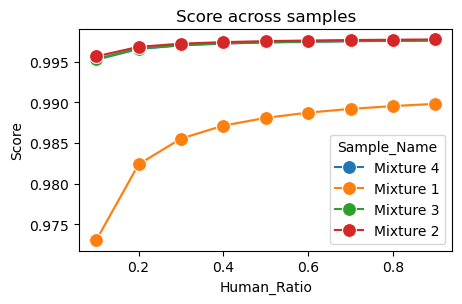

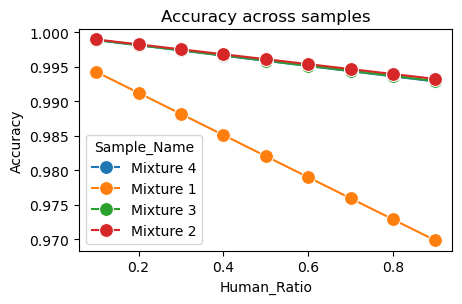

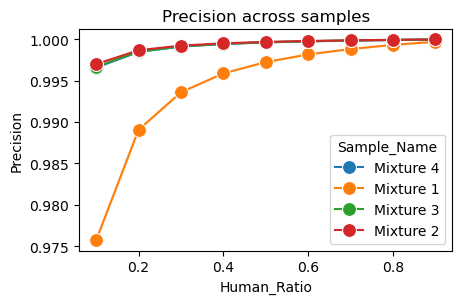

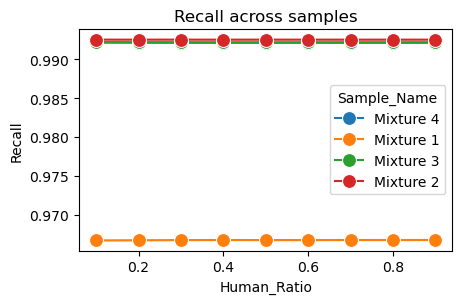

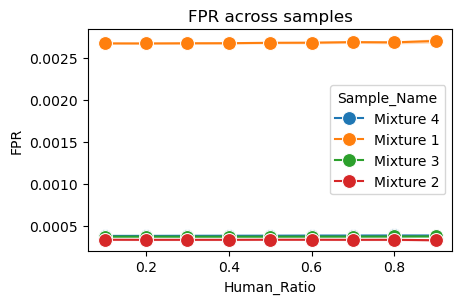

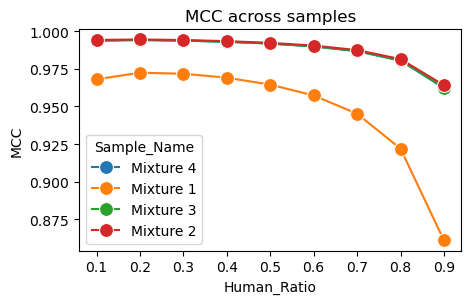

In [19]:
for metric in metrics:
    errorplot_by_sample(df_metrics, metric=metric, figsize=figsize)


### Boxplots across samples

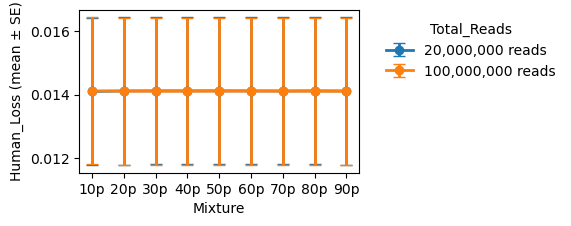

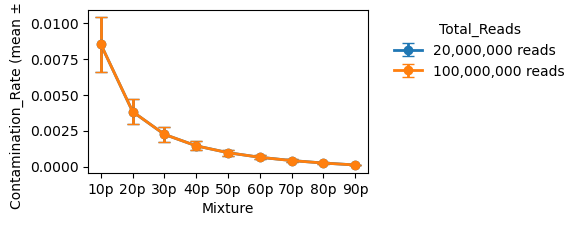

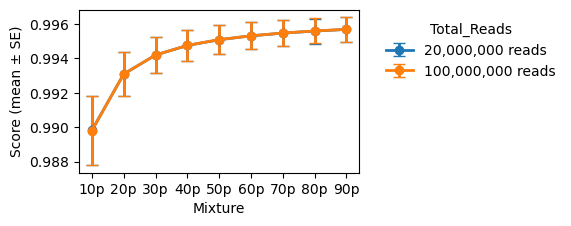

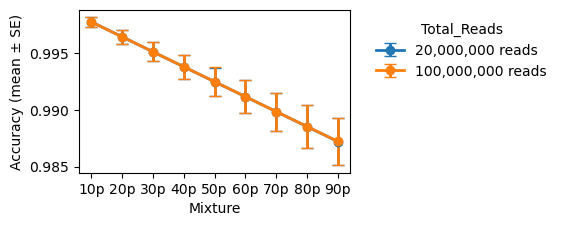

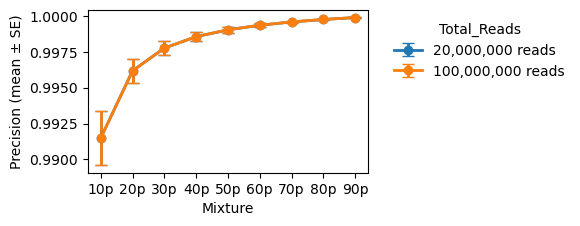

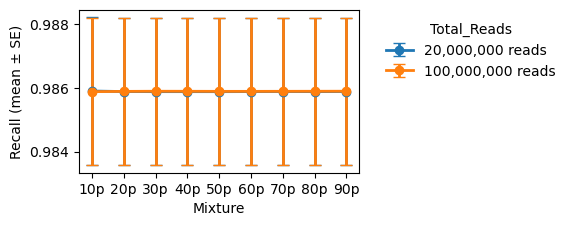

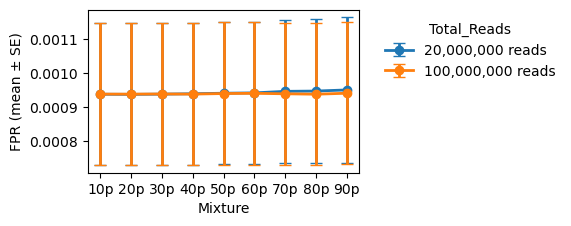

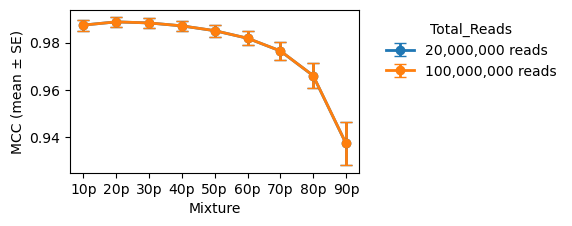

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
figsize = mm_to_inches((150, 60))
for metric in metrics:   
    plot_metric_vs_mixture(df_metrics, metric=metric, figsize=figsize)


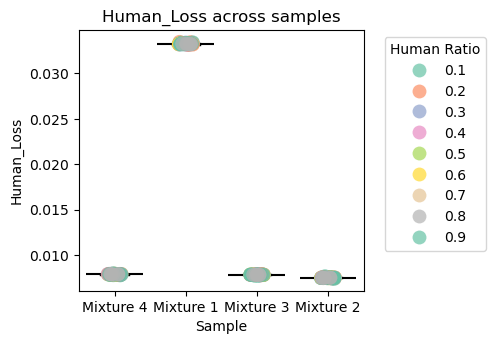

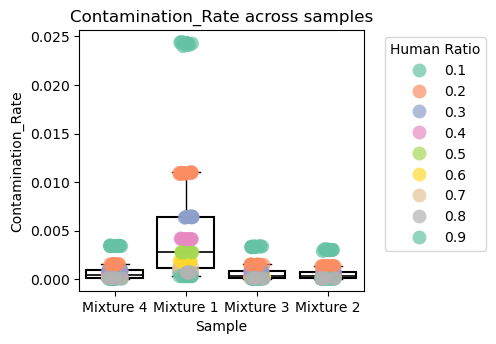

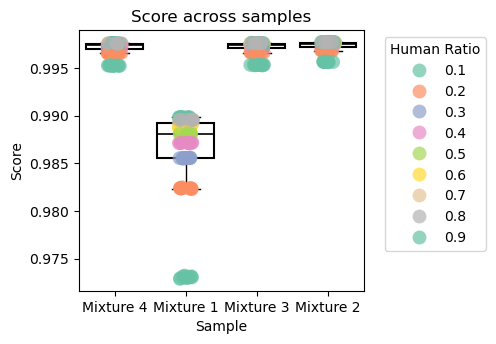

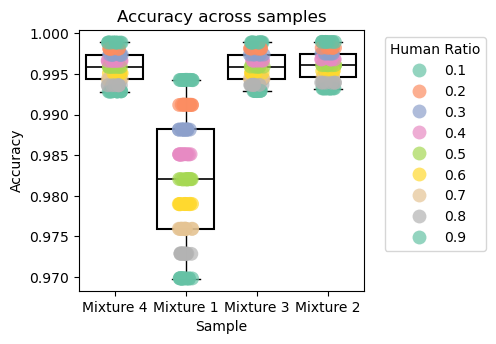

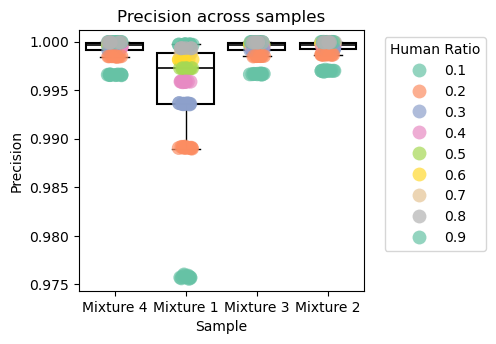

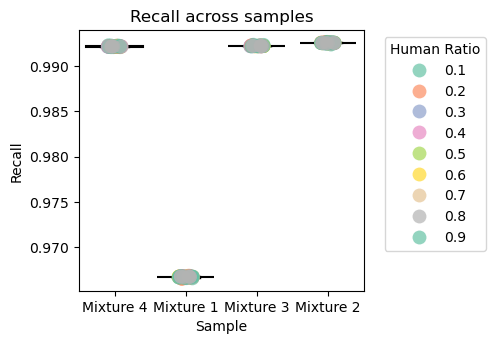

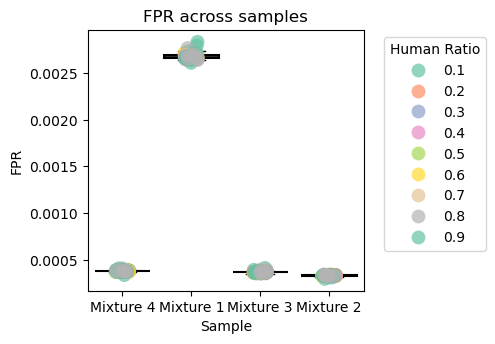

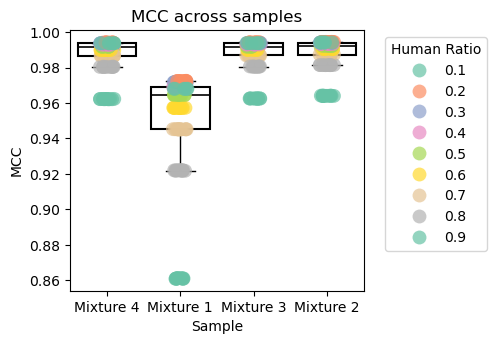

In [22]:
figsize = mm_to_inches((130, 90))
for metric in metrics:
    boxplot_by_samples(df_metrics, metric=metric, figsize=figsize, palette="Set2")


## Save dataframe

In [23]:
df_metrics["Method"] = "Xengsort"

In [25]:
out_dir = Path.cwd() / "results"
out_dir.mkdir(exist_ok=True)

df_metrics.to_csv(out_dir / "xengsort_newindex.csv", index=False)